### Import dependencies and statistics exploration

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("../data/raw/student_mental_health.csv")

df.head()
df.info()

print(df.isna().sum())
print(df.duplicated().sum())

numerical_df = df.select_dtypes(include="number")
# check each column median
for col in numerical_df.columns:
    print(f"{col} -> median = {numerical_df[col].median()}")
df.describe()







<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   object 
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   object 
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   object 
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 19

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


### outliers detection (for one feature):

In [40]:
# detect outliers
q1 = df["Age"].quantile(0.25)
q3 = df["Age"].quantile(0.75)

IQR = q3 - q1

lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

outliers = df[
    (df["Age"] < lower_bound) |
    (df["Age"] > upper_bound)
]

print(len(outliers))


4


### OUtliers reports on all conserned features

In [41]:
continuous_features = [
    "Age",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Attendance_Rate"
]

results = []

for col in continuous_features:
    # values = df[col]
    values = pd.to_numeric(df[col], errors="coerce")

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    IQR = q3 - q1

    upper_bound = q3 + 1.5 * IQR
    lower_bound = q1 - 1.5 * IQR

    mask = (values < lower_bound) | (values > upper_bound)


    results.append({

        "Feature": col,
        "Upper Bound": upper_bound,
        "Lower bound" : lower_bound,
        "outliers" : mask.sum(),
        "Percentage" : round(mask.mean() * 100, 2)
    })

outlier_report = pd.DataFrame(results)

display(outlier_report)

    


,Feature,Upper Bound,Lower bound,outliers,Percentage
0,Age,27.5000,15.5000,4,0.20
1,Sleep_Hours,10.0000,3.6000,2,0.10
2,Study_Hours_Per_Week,36.0000,4.0000,7,0.35
3,GPA,3.4950,1.6150,9,0.45
4,Social_Media_Hours,8.9125,3.0125,20,1.00
5,Screen_Time_Hours,13.1500,3.9500,7,0.35
6,Attendance_Rate,104.5500,65.7500,12,0.60


### Visualization of outliers

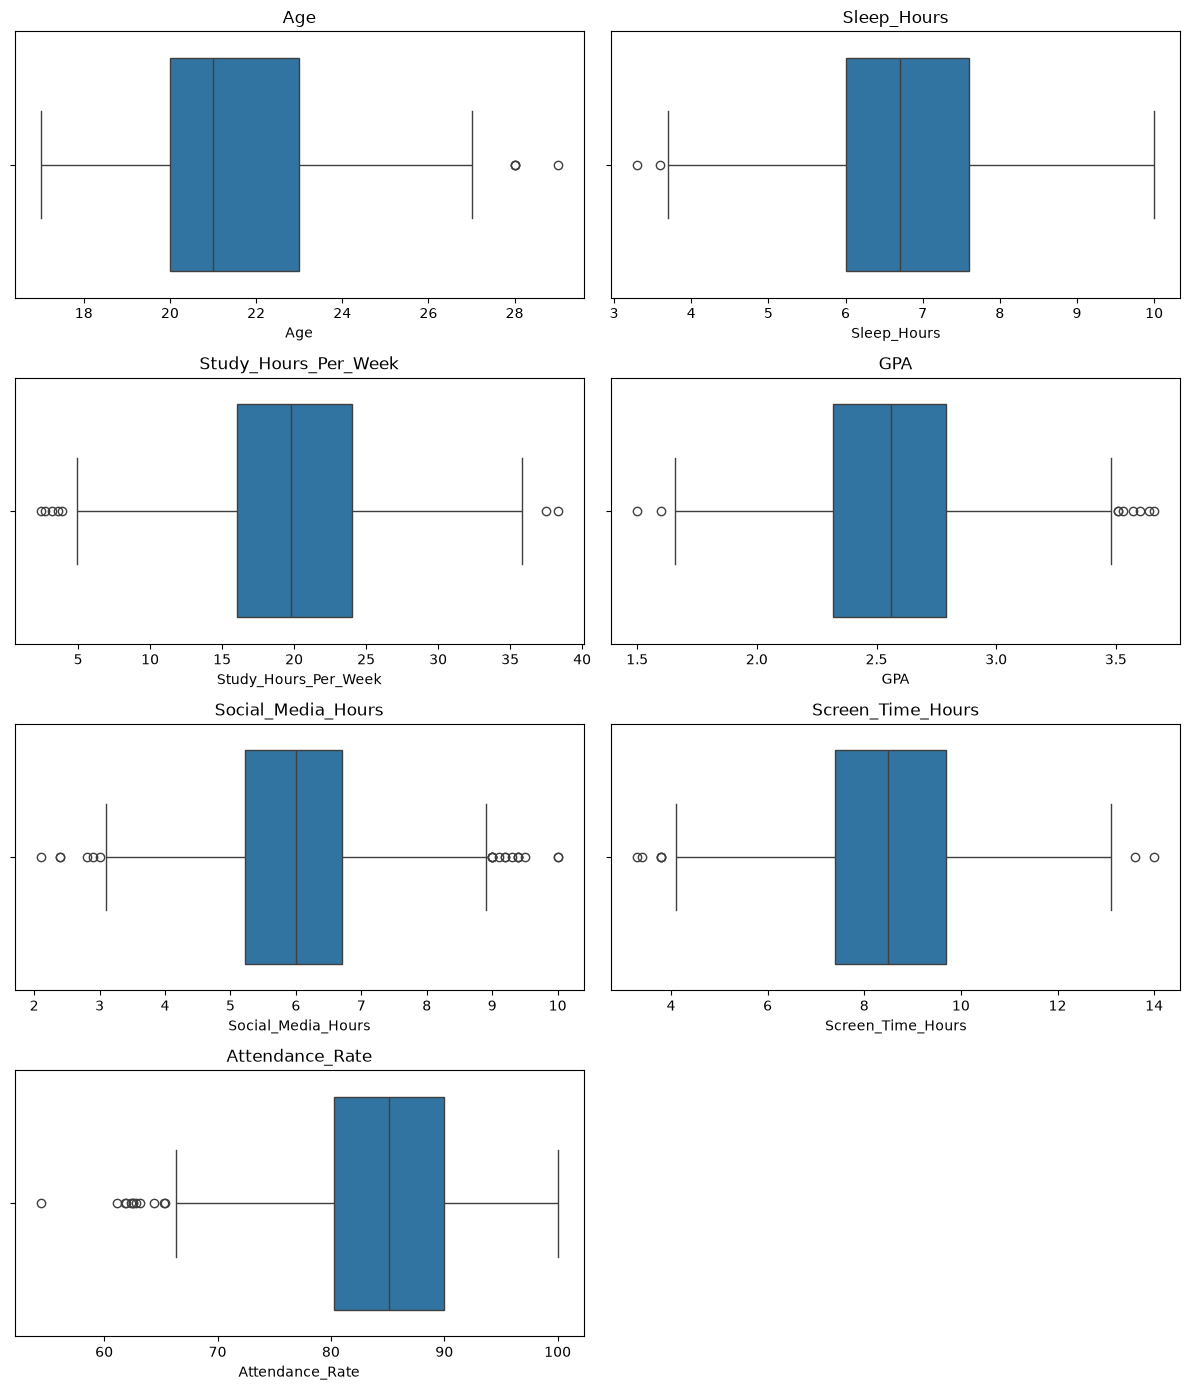

In [42]:
fig, axes = plt.subplots(
    4, 2, 
    figsize=(12, 14)
)


for ax, col in zip(axes.flat, continuous_features):
    sns.boxplot(
        x=pd.to_numeric(df[col], errors="coerce"),
        ax=ax
    )
    ax.set_title(col)

for ax in axes.flat[len(continuous_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Target distribution and class imbalance

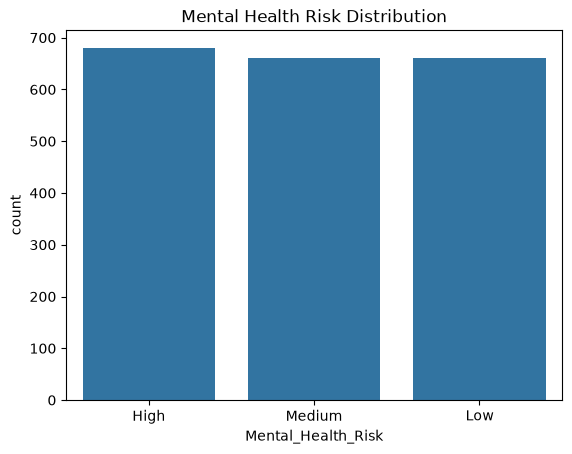

In [43]:
df["Mental_Health_Risk"].value_counts() #counts of distinct counts
df["Mental_Health_Risk"].value_counts(normalize=True) * 100 # percetange per each class in the target y feature
# as a result we got the classes are well balanced


# so as a visualizer we use countplot
sns.countplot(
    data=df,
    x="Mental_Health_Risk"
)
plt.title("Mental Health Risk Distribution")
plt.show()

### Univariate feature analysis

Age                     21.131500
Sleep_Hours              6.758875
Study_Hours_Per_Week    19.997900
GPA                      2.562503
Social_Media_Hours       6.013955
Screen_Time_Hours        8.548500
Attendance_Rate         85.080236
dtype: float64


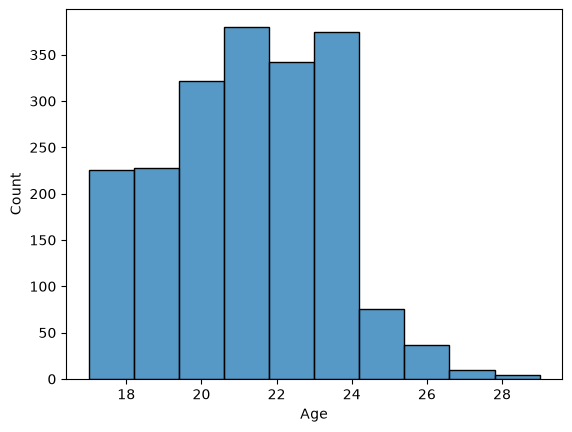

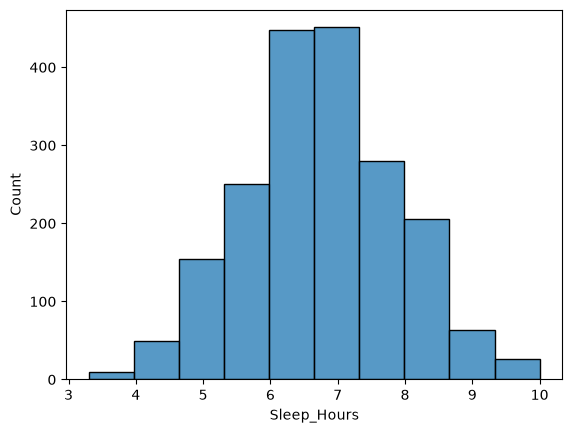

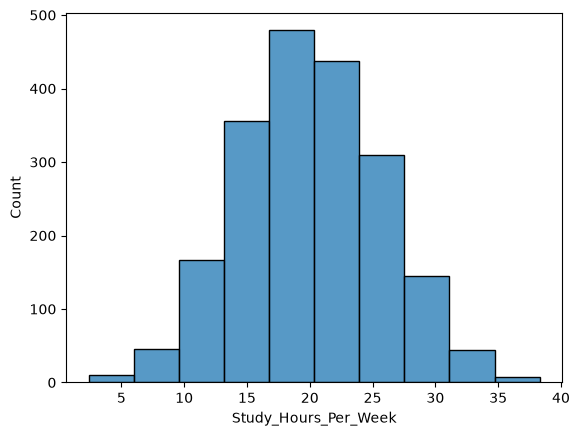

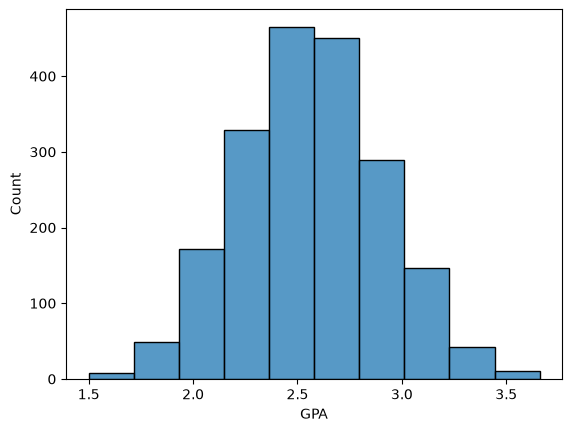

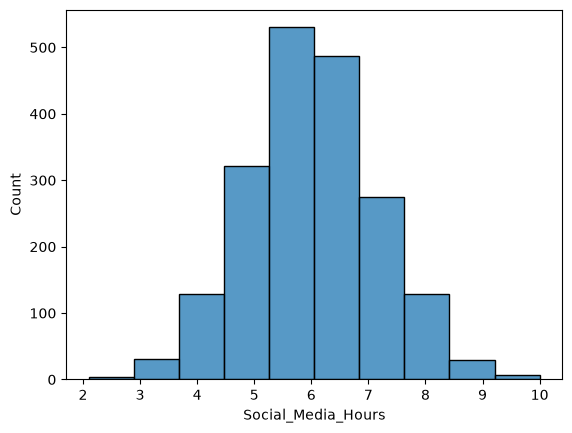

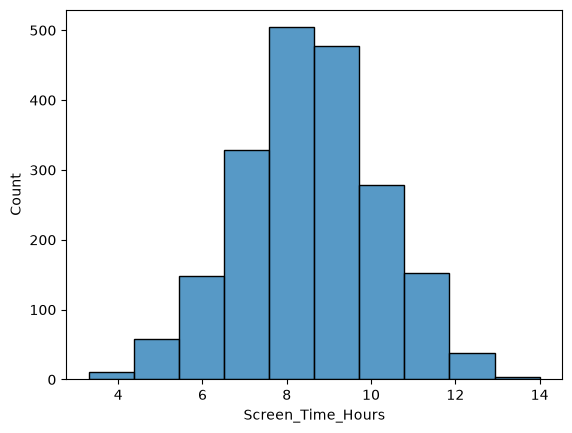

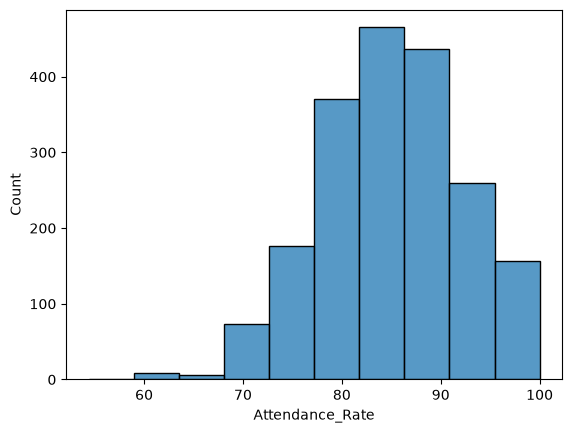

Gender      Diet_Quality  Physical_Activity  Part_Time_Job  Previous_Mental_Health_History
Male        Average       Moderate           No             No                                92
Female      Average       Moderate           No             No                                71
                          Low                No             No                                69
            Poor          Moderate           No             No                                67
Male        Poor          Moderate           No             No                                65
                                                                                              ..
Non-binary  Good          Moderate           No             Yes                                1
            Poor          High               Yes            No                                 1
                          Low                Yes            No                                 1
                                    

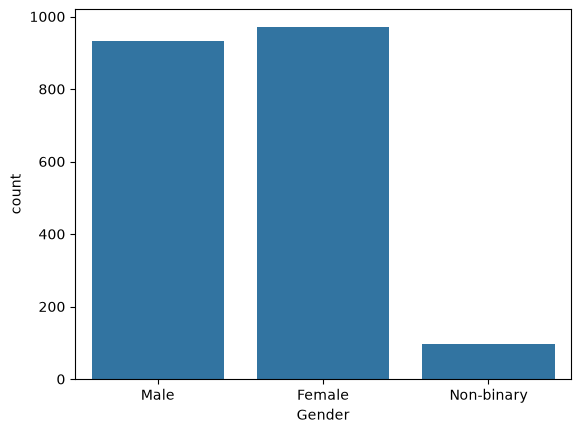

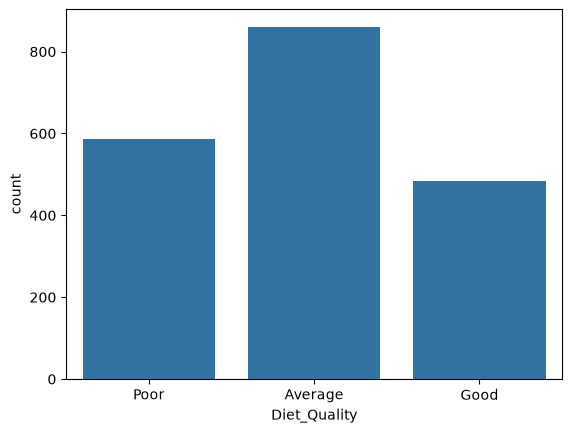

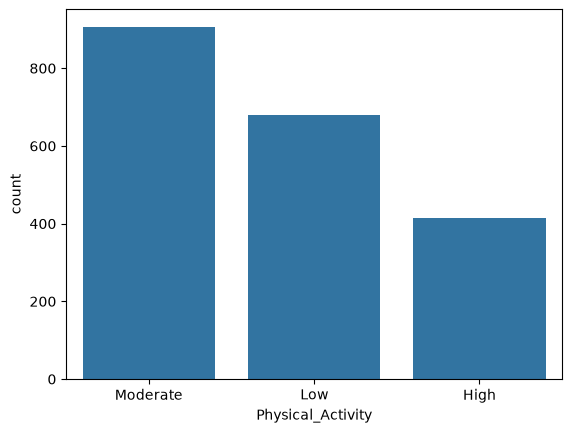

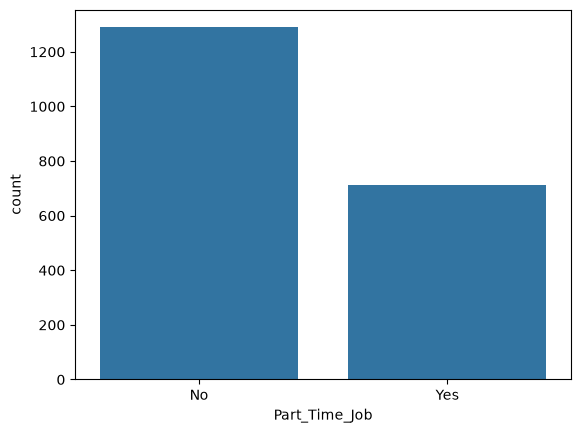

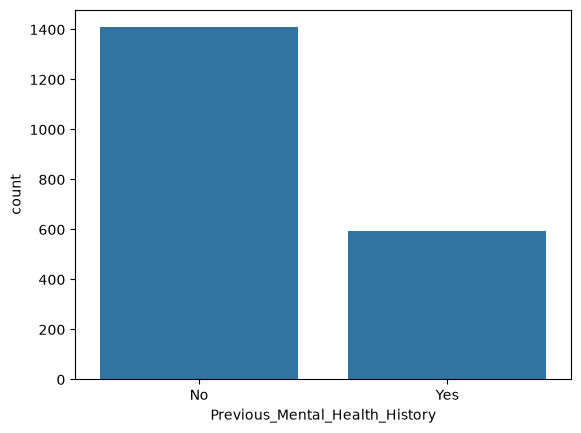

In [44]:
numerical_features = [
    "Age",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Attendance_Rate"   
]
print(df[numerical_features].mean())
for col in numerical_features:

    sns.histplot(data=df, x=col, bins=10)
    plt.show()


categorical_features = [
    "Gender",
    "Diet_Quality",
    "Physical_Activity",
    "Part_Time_Job",
    "Previous_Mental_Health_History"
]

print(df[categorical_features].value_counts())

for col in categorical_features:
    sns.countplot(data=df, x=col)
    plt.show()

### Feature vs target analysis (Bivariate analysis)

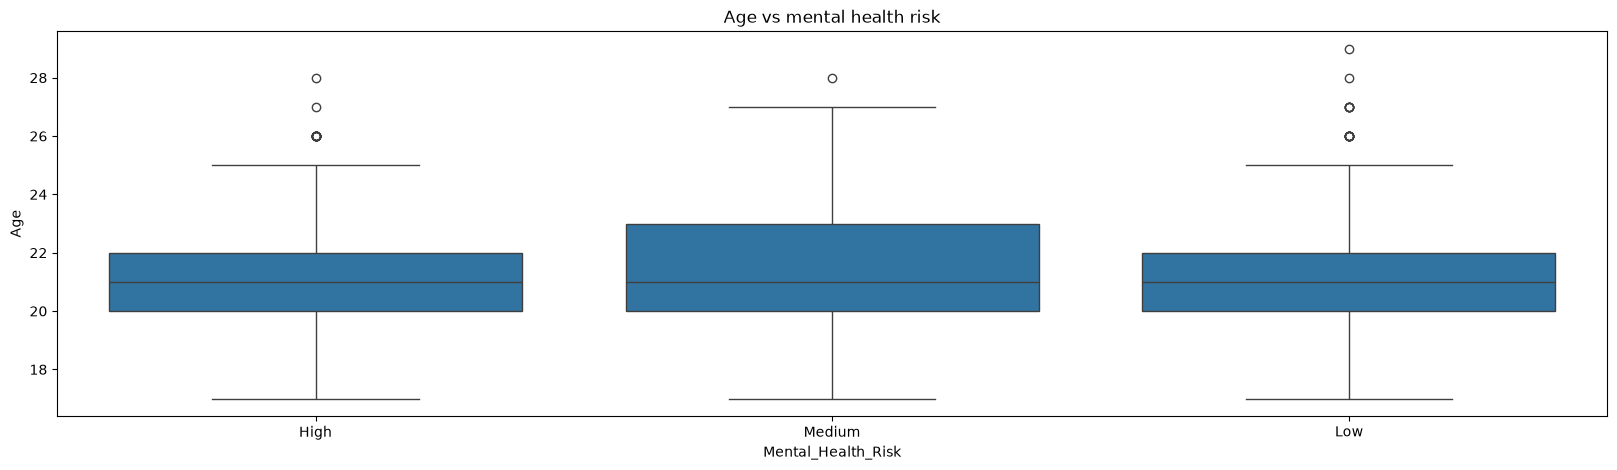

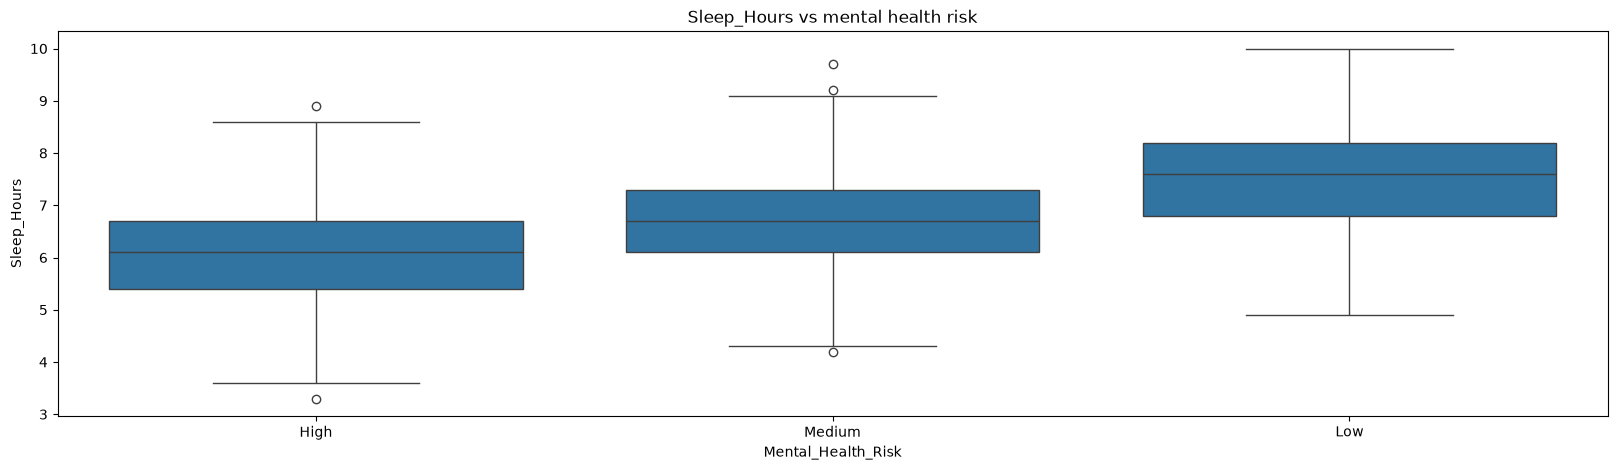

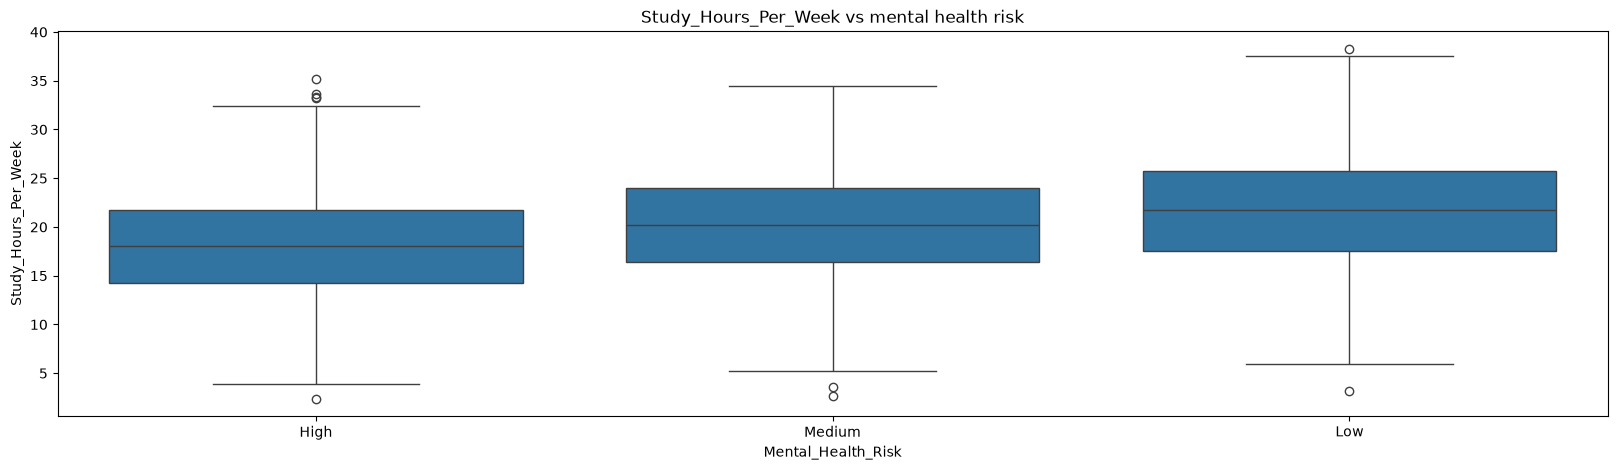

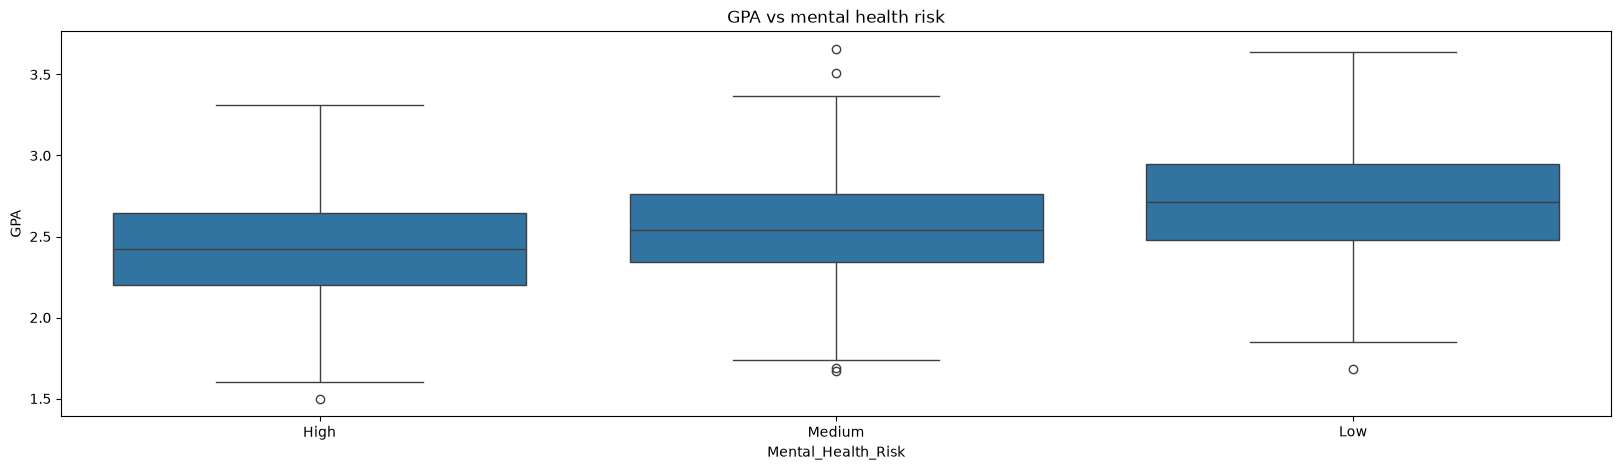

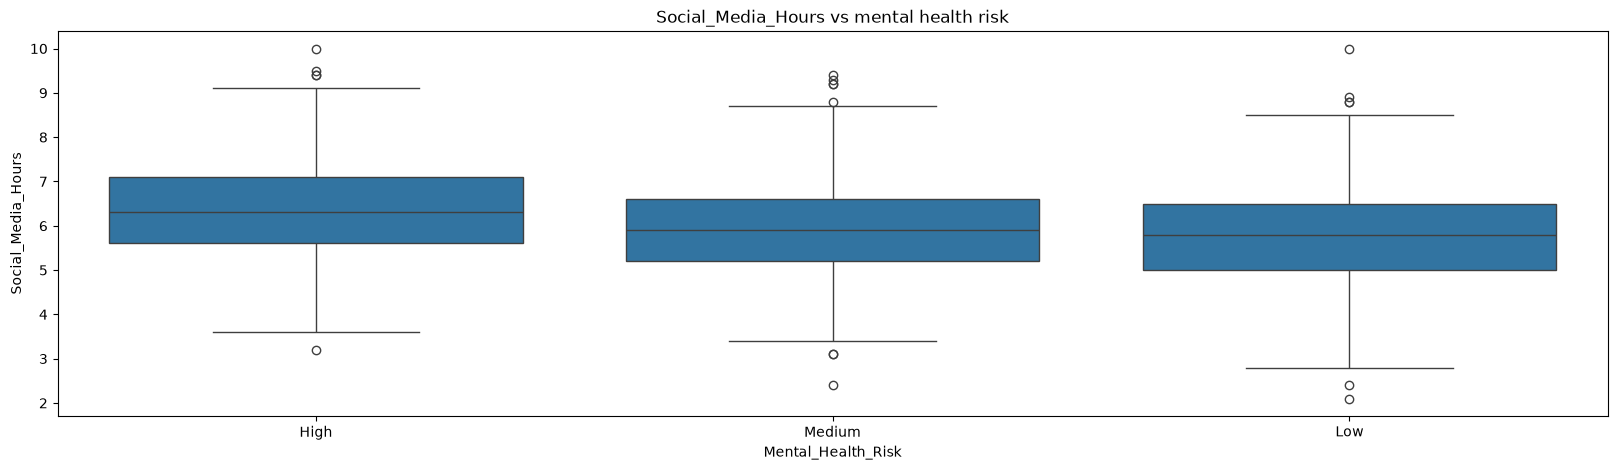

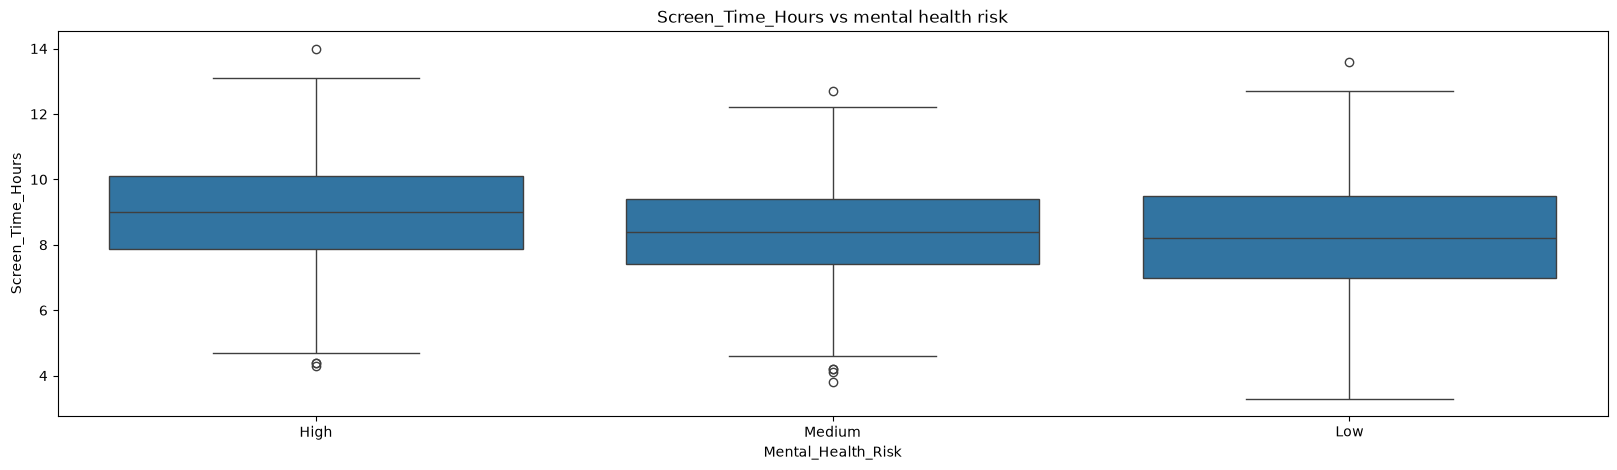

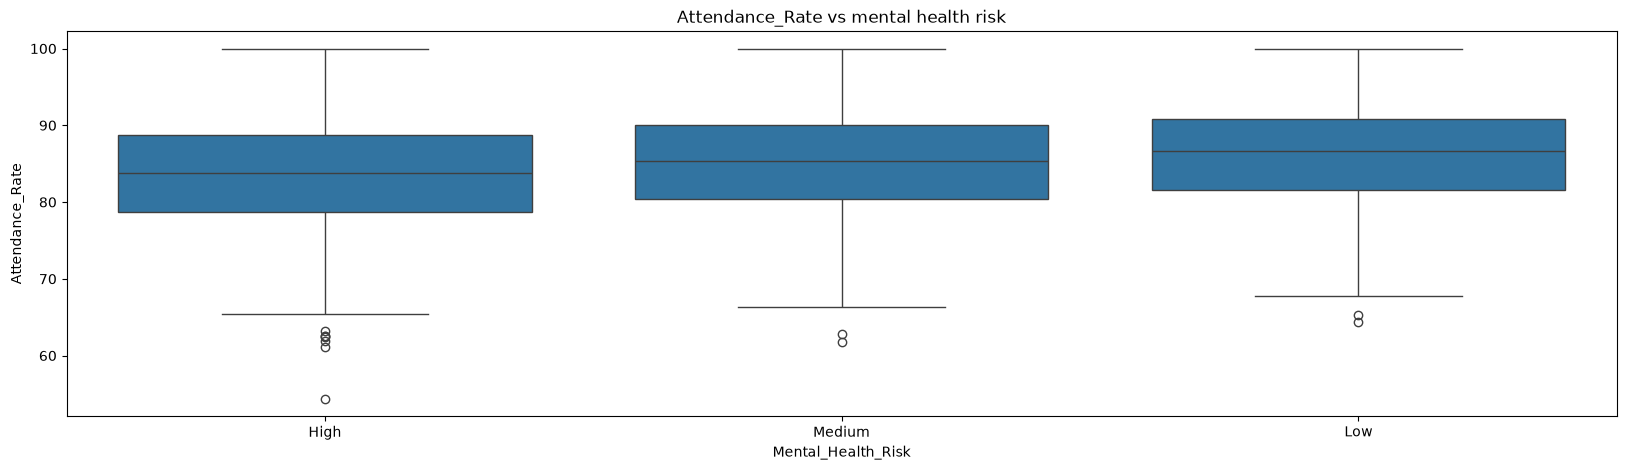

Mental_Health_Risk,High,Low,Medium
Gender,,,
Female,34.603502,33.470649,31.925850
Male,33.369099,31.759657,34.871245
Non-binary,34.020619,40.206186,25.773196


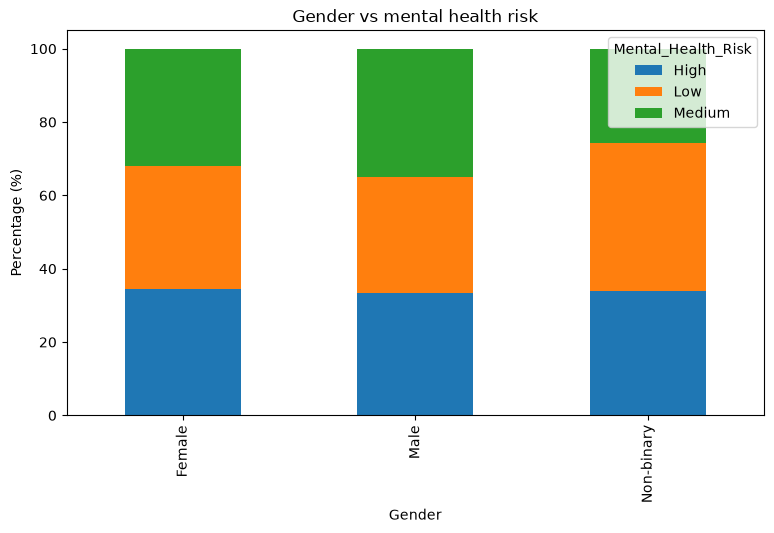

Mental_Health_Risk,High,Low,Medium
Diet_Quality,,,
Average,32.325581,33.488372,34.186047
Good,27.479339,42.768595,29.752066
Poor,42.248722,24.020443,33.730835


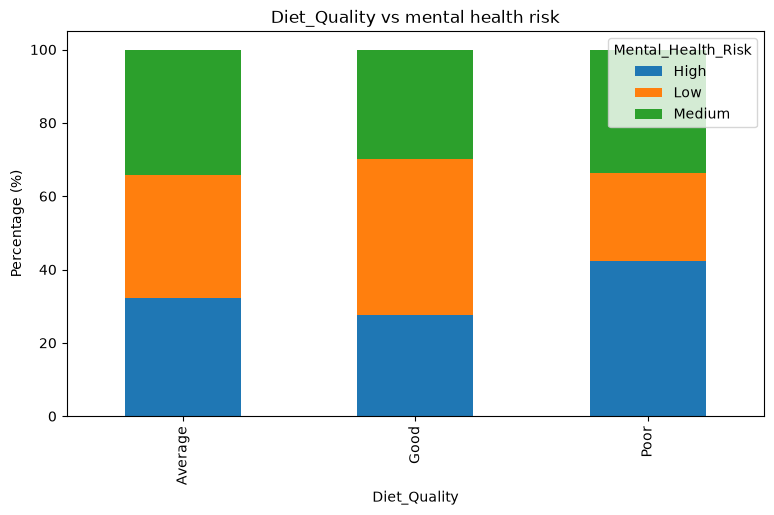

Mental_Health_Risk,High,Low,Medium
Physical_Activity,,,
High,20.240964,49.397590,30.361446
Low,45.949926,22.827688,31.222386
Moderate,31.346578,33.112583,35.540839


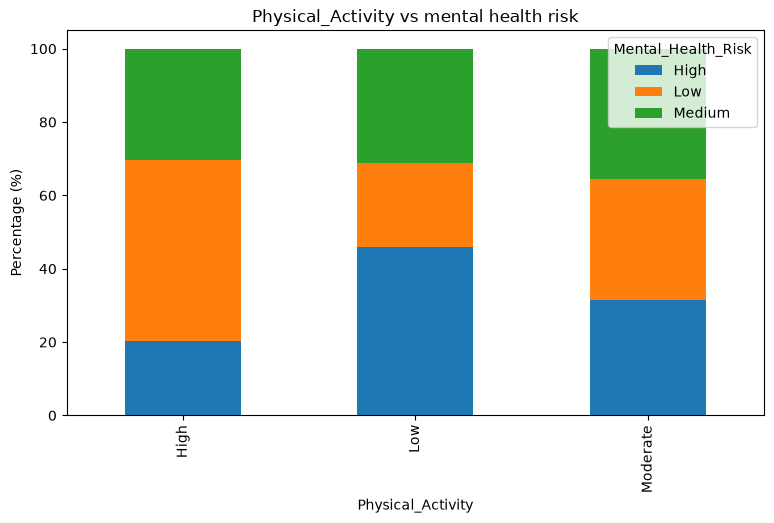

Mental_Health_Risk,High,Low,Medium
Part_Time_Job,,,
No,30.256012,36.229635,33.514352
Yes,40.787623,27.144866,32.067511


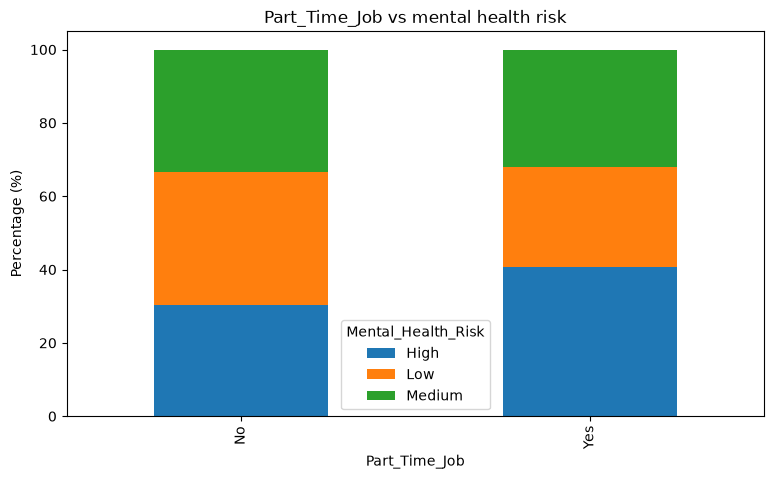

Mental_Health_Risk,High,Low,Medium
Previous_Mental_Health_History,,,
No,27.414773,39.275568,33.309659
Yes,49.662162,18.074324,32.263514


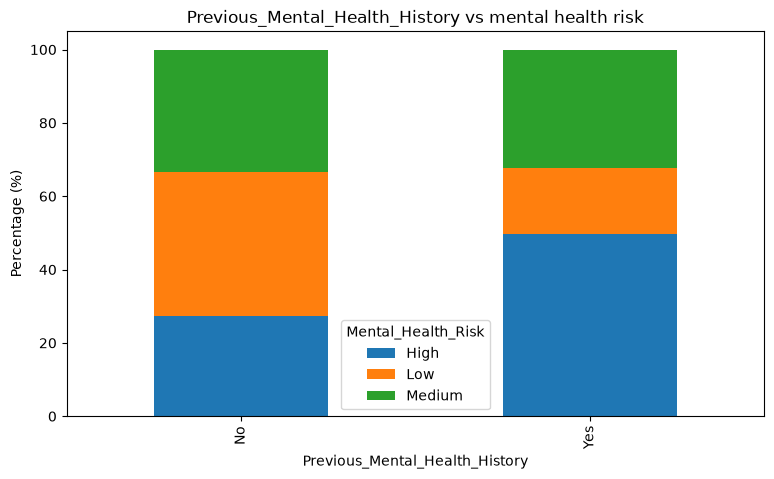

In [45]:
# studying how each feature is related to the target feature
# answer the question does students with different mental health risks have the same sleep hours

for col in numerical_features:
    plt.figure(figsize=(20, 5))

    sns.boxplot(data=df, x="Mental_Health_Risk", y=col)

    plt.title(f"{col} vs mental health risk")
    plt.show()



for col in categorical_features:

# diet quality vs mental health risk
    percentages = pd.crosstab(
        df[col], 
        df["Mental_Health_Risk"], 
        normalize="index"
    ) * 100

    display(percentages)

    percentages.plot(kind="bar",stacked=True, figsize=(9, 5))

    plt.title(f"{col} vs mental health risk")
    plt.ylabel("Percentage (%)")

    plt.show()

### Correlation analysis

,Age,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Attendance_Rate
Age,1.000000,-0.010572,-0.007476,0.001437,-0.007609,-0.005439,-0.009612
Sleep_Hours,-0.010572,1.000000,0.032237,0.246255,0.002183,0.019314,0.076609
Study_Hours_Per_Week,-0.007476,0.032237,1.000000,0.492501,-0.501178,-0.333568,0.138003
GPA,0.001437,0.246255,0.492501,1.000000,-0.225998,-0.158174,0.285952
Social_Media_Hours,-0.007609,0.002183,-0.501178,-0.225998,1.000000,0.681404,-0.067095
Screen_Time_Hours,-0.005439,0.019314,-0.333568,-0.158174,0.681404,1.000000,-0.061941
Attendance_Rate,-0.009612,0.076609,0.138003,0.285952,-0.067095,-0.061941,1.000000


,Age,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Attendance_Rate
Age,1.000000,-0.022951,-0.010781,0.005921,-0.018377,-0.002047,-0.019906
Sleep_Hours,-0.022951,1.000000,0.035684,0.242615,-0.001470,0.007128,0.066124
Study_Hours_Per_Week,-0.010781,0.035684,1.000000,0.482227,-0.488570,-0.326373,0.132236
GPA,0.005921,0.242615,0.482227,1.000000,-0.228284,-0.158266,0.274317
Social_Media_Hours,-0.018377,-0.001470,-0.488570,-0.228284,1.000000,0.669477,-0.068928
Screen_Time_Hours,-0.002047,0.007128,-0.326373,-0.158266,0.669477,1.000000,-0.061221
Attendance_Rate,-0.019906,0.066124,0.132236,0.274317,-0.068928,-0.061221,1.000000


strongest correlation


Social_Media_Hours    Screen_Time_Hours     0.681404
Study_Hours_Per_Week  Social_Media_Hours   -0.501178
                      GPA                   0.492501
                      Screen_Time_Hours    -0.333568
GPA                   Attendance_Rate       0.285952
dtype: float64

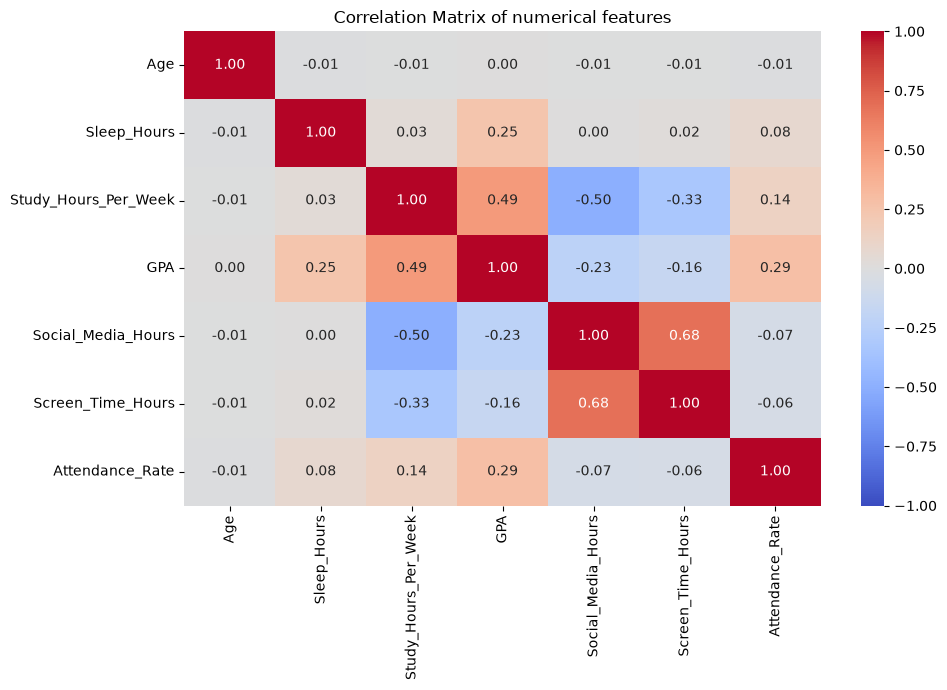

In [46]:
# correlation tells us whether two variables tend to change together for exp: study hours & gpa
# now lets study the linear correlation 

correlation_matrix = df[numerical_features].corr(method="pearson")
display(correlation_matrix)
correlation_matrix_2 = df[numerical_features].corr(method="spearman")
display(correlation_matrix_2)


upper = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

strongest = (
    upper.stack()
    .sort_values(key=abs, ascending=False)
)
print("strongest correlation")
display(strongest.head(5))
# for visualization we use a heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix, 
    annot=True, 
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix of numerical features")
plt.tight_layout()
plt.show()

### EDA conclusions


### Dataset overview
The dataset contains **2,000 observations and 17 columns**, including the target variable `Mental_Health_Risk`, which has three categories: Low, Medium, and High.

### Data quality
Seven features contain missing values. `Financial_Stress` has the highest missing-value percentage (4.55%), followed by `Diet_Quality` (3.45%) and `Sleep_Hours` (3.10%).

No completely duplicated rows were detected. Identifier uniqueness and categorical value validity should also be checked.

### Outlier analysis
The IQR method identified potential outliers in several numerical features, including `Social_Media_Hours` (20 observations), `Attendance_Rate` (12), and `GPA` (9).

These observations should be evaluated against valid feature ranges before any treatment. Statistical outliers are not necessarily erroneous observations.

### Numerical distributions
The average student age is approximately 21.13 years, the average sleep duration is 6.76 hours, and the average study duration is approximately 20 hours per week.

The mean GPA is approximately 2.56. The distribution shapes should be documented after reviewing the histograms.

### Correlation analysis
The saved Pearson correlation results indicate a positive association between weekly study hours and GPA (r ≈ 0.493), as well as a weaker positive association between sleep duration and GPA (r ≈ 0.246).

The full seven-feature correlation matrix should be regenerated before drawing final conclusions about feature redundancy.

### Preprocessing recommendations
- Exclude `Student_ID` from predictive features.
- Split the dataset into training and independent test sets before fitting preprocessing transformations.
- Fit numerical and categorical imputers on training data only.
- Encode categorical variables according to their meaning.
- Apply scaling where required by the selected classification algorithms.
- Evaluate class imbalance and consider class weights or training-only resampling if necessary.
- Retain plausible unusual observations unless a justified treatment is established.
- Compare feature-selection decisions through cross-validation.

### Conclusion
The EDA has identified missing data, potential outliers, and associations between several numerical features. Further validation of the target distribution, feature-target visualizations, and full correlation matrix is required before finalizing preprocessing decisions.

This dataset is used for an educational machine-learning exercise and should not be treated as a clinically validated mental-health assessment tool.

###